# Lecture 18, Bias correction

> Removing the systematic errors of a climate model before it is used in hydrology

Lecture 14 (Section 4) listed bias correction as the first post-processing step between a climate model and a catchment model, and Lecture 16 set out the downscaling problem. Lecture 17 supplied the statistics: the CDF, quantiles, plotting positions and the gamma and normal distributions. This lecture puts them to work on the simplest and most widely used of all downscaling tools. Take a climate model run for 1981&ndash;2000 over a monsoon catchment and compare it with the rain gauges:

- It rains on **almost every day** in the model, mostly a fraction of a millimetre, while the gauges are dry on half of the days.
- Its heavy rain is **too weak**, so the 95th percentile of wet-day rain is far below the observed one.
- It is **3 &deg;C too cold** and too variable.

A flood or water-balance model driven by such a series would be wrong before any hydrology starts. The model also says the climate will change: how do we repair the bias **without destroying that change**?

By the end of this lecture you should be able to:

- explain why bias correction is needed and **what it cannot fix**,
- adjust the **occurrence** of model rainfall with a wet-day threshold and explain the drizzle problem,
- apply the **delta method**, choosing the additive form for temperature and the multiplicative form for rainfall, and recognise the danger of ratios near zero,
- **derive quantile mapping** from matching probabilities, fit it with gamma and normal distributions, and build the empirical version with interpolation and extrapolation,
- **derive quantile delta mapping** (QDM), and show that it keeps the model's projected relative change in every quantile while plain quantile mapping can distort it,
- compare the methods and **validate** them on held-out data with a handful of metrics.

The companion workbook `data/downscaling/lec18/lec18_worked_examples.xlsx` repeats the calculations of Sections 3 to 8 with live formulas, and each section says which sheet to open. All data in this lecture are **synthetic**.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas scipy matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

# 1) Why bias correction, and what it cannot fix

Write $x_h$ for the model value in the **historical** (calibration) period, $x_f$ for the model value in the **future**, $y$ for the observation, and $\hat y$ for a corrected value. A model has a **bias** when the *distribution* of $x_h$ differs from the distribution of $y$ over the same years: its mean, its spread, its frequency of rain days or its tail are off. The causes are structural and are not removed by a better random seed:

- a model grid cell of 100&ndash;250 km averages over terrain that a gauge in a Himalayan valley or on the Western Ghats does not (scale and elevation, Lecture 16),
- convection and cloud are **parameterised**, and models typically rain too often and too lightly (the *drizzle problem*),
- coarse orography smooths the rain bands that the real mountains concentrate.

**Bias correction** is a mapping $\hat y = g(x)$ that is fitted on the calibration period, where we have both $x_h$ and $y$, and then applied to the model's future values. In symbols: choose $g$ so that the distribution of $g(x_h)$ matches that of $y$, then compute $\hat y_f = g(x_f)$. The method rests on one assumption, **stationarity of the bias**: a correction fitted on the past is still the right correction in a different climate. Section 6 shows how this assumption is used and where it hurts.

Three things are therefore never repaired by bias correction:

1. **Timing.** A free-running model is not a forecast. Its wet day need not coincide with the gauge's wet day, so the correction acts on the *distribution*; we judge it with distribution statistics (Section 8), never day by day.
2. **Wrong processes.** If the model delays the monsoon onset, misplaces the rain band or misses the ENSO teleconnection, rescaling the amounts does not cure the mechanism. A corrected series can look right and still be wrong for the wrong reasons.
3. **A wrong projected change.** The correction *carries the model's signal through*. If the model's warming or rainfall change is unrealistic, the corrected one is too.

Other limits are consequences of correcting one variable at one place at a time. The relation between rain and temperature, and between neighbouring cells, is not repaired, and a spatial mismatch between cell and gauge is only partly a bias (Lecture 23). Finally, a good fit in the calibration period proves little because the method forces it, so every correction must be **validated on data that were not used to fit it** (Section 8).

# 2) A laboratory: synthetic observations, model and truth

With real model data we never see the truth about the future, so we build a laboratory (in the spirit of the energy-balance toy model of Lecture 14). Everything below is generated for teaching and is **synthetic**. We simulate 20 monsoon seasons (June to September, 122 days per season, 2440 days) for each of six series:

| name | meaning |
|:--|:--|
| `obs_cal`, `mod_cal` | observation and model, **calibration** seasons (used to fit every correction) |
| `obs_val`, `mod_val` | observation and model, **validation** seasons: another 20 seasons of the *same* climate, held out |
| `mod_fut` | model **future**, with a climate-change signal |
| `tru_fut` | the **truth** for the future, which a perfect correction should reproduce |

Each daily value is generated from a persistent uniform random number $u$ (days are autocorrelated) by an inverse CDF, so the biases and the change signal are known exactly:

- **Observed rain**: wet on 55 % of days, wet-day rain gamma with shape 0.55 and scale 20 mm, recorded to 0.1 mm. **Model rain**: wet on 93 % of days, gamma shape 0.6 and scale 6 mm (a drizzle-heavy, light-tailed model).
- **Climate change in rain**: the quantile of probability $\tau$ is multiplied by $c(\tau)=1.05+0.40\,\tau^{6}$, so the median rises by about 6 % and the heaviest days by about 40 %. The model and the truth receive the **same relative change**; this is the situation in which a good method should recover the truth.
- **Temperature**: observed normal with mean 30 &deg;C and standard deviation 2.2 &deg;C; model mean 27 &deg;C and standard deviation 3.0 &deg;C (cold and too variable). Warming of $d(\tau)=2.4+1.6\,\tau$ &deg;C at probability $\tau$ (hot days warm more), applied to model and truth alike.

The random numbers are stored in `data/downscaling/lec18/lec18_uniform_numbers.csv`, the parameters in `lec18_scenario_parameters.csv`, and the finished series in `lec18_synthetic_series.csv`. The cell below holds the generator (the same formulas are in the workbook, sheets `Params` and `Data`) and reads the random numbers, regenerating them if the file is not on this machine.

**Using real data instead.** Replace `obs_*` by an observed series (for example an IMD gridded or station record for your catchment) and `mod_*` by the same cell from a CMIP6 or NEX-GDDP-CMIP6 simulation (`historical` for the first two periods, a scenario for `mod_fut`); then drop `tru_fut`, which exists only in a laboratory.

In [3]:
NYEARS, NDAYS = 20, 122          # 20 monsoon seasons (JJAS) of 122 days
N = NYEARS * NDAYS
PARAMS = dict(
    fo=0.55, ko=0.55, so=20.0,        # observed rain: wet-day fraction, gamma shape, gamma scale (mm)
    fm=0.93, km=0.60, sm=6.0,         # model rain
    ca=1.05, cb=0.40, cp=6,           # climate-change factor c(tau)=ca+cb*tau^cp (rain)
    muo=30.0, sdo=2.2,                # observed temperature (degC)
    mum=27.0, sdm=3.0,                # model temperature
    da=2.4, db=1.6,                   # warming d(tau)=da+db*tau (degC)
)
COLS = ["obs_cal", "mod_cal", "obs_val", "mod_val", "mod_fut", "tru_fut"]


def _ar1_uniform(rng, n, rho):
    z = np.empty(n)
    z[0] = rng.standard_normal()
    e = rng.standard_normal(n) * np.sqrt(1 - rho**2)
    for t in range(1, n):
        z[t] = rho * z[t - 1] + e[t]
    return stats.norm.cdf(z)


def make_uniforms(seed=18):
    rng = np.random.default_rng(seed)
    uP = {c: _ar1_uniform(rng, N, 0.35) for c in COLS}
    uT = {c: _ar1_uniform(rng, N, 0.70) for c in COLS}
    return uP, uT


def rain_obs(u, p, c=None):
    w = np.clip((u - (1 - p["fo"])) / p["fo"], 1e-12, 1 - 1e-12)
    x = stats.gamma.ppf(w, p["ko"], scale=p["so"])
    if c is not None:
        x = x * c
    return np.where(u <= 1 - p["fo"], 0.0, np.maximum(0.1, np.round(x, 1)))


def rain_mod(u, p, c=None):
    w = np.clip((u - (1 - p["fm"])) / p["fm"], 1e-12, 1 - 1e-12)
    x = stats.gamma.ppf(w, p["km"], scale=p["sm"])
    if c is not None:
        x = x * c
    return np.where(u <= 1 - p["fm"], 0.0, np.round(x, 3))


def cfac(u, p):
    return p["ca"] + p["cb"] * u ** p["cp"]


def temp_obs(u, p, d=None):
    x = stats.norm.ppf(u, p["muo"], p["sdo"])
    if d is not None:
        x = x + d
    return np.round(x, 1)


def temp_mod(u, p, d=None):
    x = stats.norm.ppf(u, p["mum"], p["sdm"])
    if d is not None:
        x = x + d
    return np.round(x, 2)


def dwarm(u, p):
    return p["da"] + p["db"] * u


def make_series(uP, uT, p=PARAMS):
    P = dict(obs_cal=rain_obs(uP["obs_cal"], p), mod_cal=rain_mod(uP["mod_cal"], p),
             obs_val=rain_obs(uP["obs_val"], p), mod_val=rain_mod(uP["mod_val"], p),
             mod_fut=rain_mod(uP["mod_fut"], p, cfac(uP["mod_fut"], p)),
             tru_fut=rain_obs(uP["tru_fut"], p, cfac(uP["tru_fut"], p)))
    T = dict(obs_cal=temp_obs(uT["obs_cal"], p), mod_cal=temp_mod(uT["mod_cal"], p),
             obs_val=temp_obs(uT["obs_val"], p), mod_val=temp_mod(uT["mod_val"], p),
             mod_fut=temp_mod(uT["mod_fut"], p, dwarm(uT["mod_fut"], p)),
             tru_fut=temp_obs(uT["tru_fut"], p, dwarm(uT["tru_fut"], p)))
    return P, T


def load_uniforms():
    """Read the stored random numbers; fall back to the repository URL, then to regenerating them."""
    name = "lec18_uniform_numbers.csv"
    for src in ("data/downscaling/lec18/" + name,
                "https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/downscaling/lec18/" + name):
        try:
            d = pd.read_csv(src)
            return ({k: d["u_rain_" + k].to_numpy() for k in COLS}, {k: d["u_temp_" + k].to_numpy() for k in COLS}, src)
        except Exception:
            pass
    uP_, uT_ = make_uniforms()
    return ({k: np.round(v, 6) for k, v in uP_.items()}, {k: np.round(v, 6) for k, v in uT_.items()}, "regenerated")


uP, uT, source = load_uniforms()
P, T = make_series(uP, uT)           # dictionaries of daily rain [mm] and temperature [degC]
print("random numbers from:", source, "   days per series:", len(P["obs_cal"]))

rows = []
for k in COLS:
    w = P[k][P[k] > 0]
    rows.append({"series": k, "rain mean [mm/d]": P[k].mean(), "wet-day fraction": np.mean(P[k] > 0),
                 "mean wet-day rain [mm]": w.mean(), "wet-day P95 [mm]": np.percentile(w, 95),
                 "T mean [degC]": T[k].mean(), "T std [degC]": T[k].std(ddof=1)})
pd.DataFrame(rows).set_index("series").round(2)

random numbers from: data/downscaling/lec18/lec18_uniform_numbers.csv    days per series: 2440


,rain mean [mm/d],wet-day fraction,mean wet-day rain [mm],wet-day P95 [mm],T mean [degC],T std [degC]
series,,,,,,
obs_cal,6.15,0.54,11.38,45.10,29.89,2.08
mod_cal,3.28,0.92,3.56,12.47,26.77,2.90
obs_val,6.24,0.56,11.07,41.35,30.03,2.24
mod_val,3.30,0.92,3.59,13.02,26.97,2.99
mod_fut,4.11,0.92,4.45,18.50,29.99,3.56
tru_fut,8.23,0.56,14.76,60.10,32.95,2.58


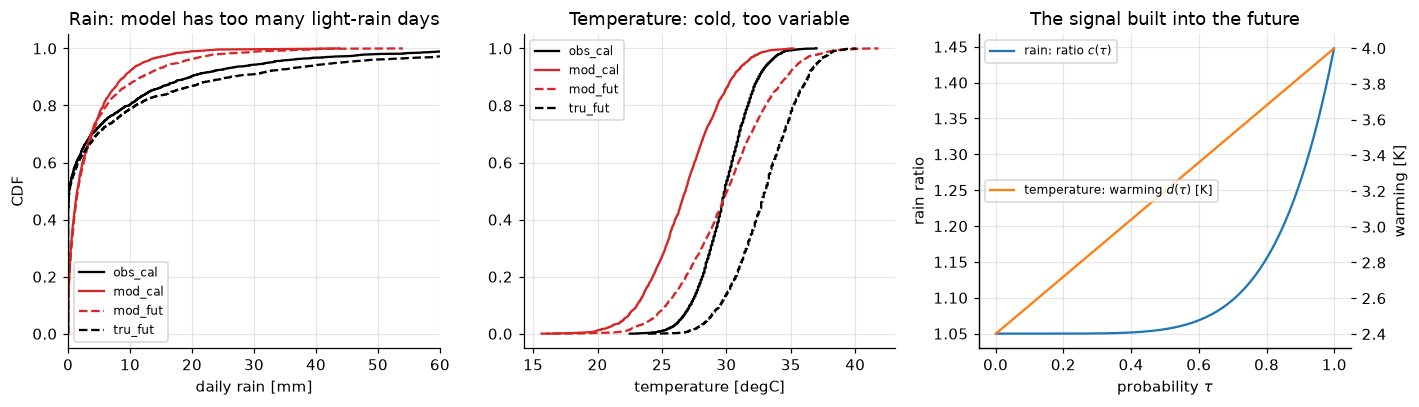

In [4]:
tg = np.linspace(0.001, 0.999, 500)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for k, c, ls in (("obs_cal", "k", "-"), ("mod_cal", "tab:red", "-"), ("mod_fut", "tab:red", "--"), ("tru_fut", "k", "--")):
    xs = np.sort(P[k]); ax[0].plot(xs, np.arange(1, len(xs) + 1) / len(xs), c=c, ls=ls, label=k)
    xs = np.sort(T[k]); ax[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), c=c, ls=ls, label=k)
ax[0].set(xlim=(0, 60), xlabel="daily rain [mm]", ylabel="CDF", title="Rain: model has too many light-rain days"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="temperature [degC]", title="Temperature: cold, too variable"); ax[1].legend(fontsize=8)
ax[2].plot(tg, 1.05 + 0.40 * tg**6, "tab:blue", label="rain: ratio $c(\\tau)$")
ax[2].set(xlabel="probability $\\tau$", ylabel="rain ratio", title="The signal built into the future")
ax2 = ax[2].twinx(); ax2.plot(tg, 2.4 + 1.6 * tg, "tab:orange", label="temperature: warming $d(\\tau)$ [K]"); ax2.set_ylabel("warming [K]"); ax2.grid(False)
ax[2].legend(loc="upper left", fontsize=8); ax2.legend(loc="center left", fontsize=8)
fig.tight_layout();

The model's CDF rises almost at once (rain on nearly every day) and then lags behind the observed CDF for heavy rain; its temperature curve is shifted left and is flatter. Both futures move to the right, and the heavy-rain and hot ends move the most. The truth (black dashed) is what we want to recover.

# 3) Occurrence adjustment of precipitation

**Why first.** A gauge records no rain below about 0.1 mm, and about half of the monsoon days here are dry. The model has a trace of rain on almost every day. If we apply a correction to such a series we would be stretching drizzle, and a hydrological model driven by 93 % wet days would keep the soil moist, evaporate the water and almost never produce the infiltration-excess runoff of an intense short storm. So the wet-day *frequency* is repaired first, and only then the wet-day *intensities*.

**Derivation.** Let $f_o$ be the fraction of observed days with $y>0$ (the wet-day fraction), $F_m$ the CDF of the model's daily rain over *all* days (including its drizzle), and $t$ a threshold. The model has rain above $t$ on a fraction $P(X>t)=1-F_m(t)$ of days. We want this to be $f_o$:

$$1-F_m(t)=f_o\quad\Longrightarrow\quad \boxed{\,t=F_m^{-1}(1-f_o)\,}$$

so $t$ is the $(1-f_o)$ quantile of the model's calibration rainfall. Then set

$$x' = \begin{cases} x & x>t\\ 0 & x\le t\end{cases}$$

*Numerical sense-check.* If the model has $n=2440$ days and the observations are wet on 55 % of them, $t$ is the value that 1342 model days exceed, namely the 45 % quantile; after the adjustment 1342 model days remain wet.

The threshold is found on the **calibration** period only and then used unchanged for the validation and future series, so the future wet-day frequency is allowed to change with the model. The physical reading is reasonable: a trace of rain is below what a gauge would register, so it counts as dry. The threshold is a property of the model, the place and the season (in practice it is found month by month; here we use a single monsoon season). Sheet `Occurrence` of the workbook does exactly this: cell `B8` holds the threshold and the table below it shows the wet-day fraction as a function of threshold.

observed wet-day fraction            : 0.540
raw model wet-day fraction           : 0.922
model threshold t = F_m^-1(1 - f_o)  : 1.207 mm/day
adjusted model wet-day fraction (cal): 0.540
adjusted model wet-day fraction (val): 0.542    (fut): 0.557
mean wet-day rain, raw model 3.56 mm, adjusted 5.77 mm, observed 11.38 mm


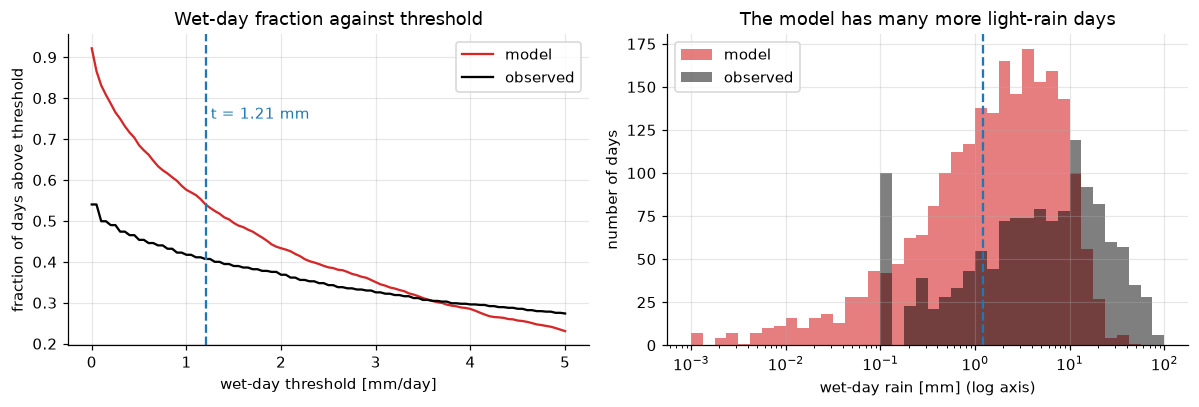

In [5]:
# ---------- occurrence adjustment ----------
def occ_threshold(obs, mod):
    """Model threshold that gives the model the observed wet-day fraction."""
    f_wet = np.mean(obs > 0)
    return np.percentile(mod, 100 * (1 - f_wet))


def occ_adjust(mod, thr):
    return np.where(mod > thr, mod, 0.0)


def wet_stats(x):
    w = x[x > 0]
    return w.mean(), w.std(ddof=1)


thr = occ_threshold(P["obs_cal"], P["mod_cal"])
adj = {k: occ_adjust(P[k], thr) for k in ("mod_cal", "mod_val", "mod_fut")}   # same threshold for every period

print(f"observed wet-day fraction            : {np.mean(P['obs_cal'] > 0):.3f}")
print(f"raw model wet-day fraction           : {np.mean(P['mod_cal'] > 0):.3f}")
print(f"model threshold t = F_m^-1(1 - f_o)  : {thr:.3f} mm/day")
print(f"adjusted model wet-day fraction (cal): {np.mean(adj['mod_cal'] > 0):.3f}")
print(f"adjusted model wet-day fraction (val): {np.mean(adj['mod_val'] > 0):.3f}    (fut): {np.mean(adj['mod_fut'] > 0):.3f}")
print(f"mean wet-day rain, raw model {P['mod_cal'][P['mod_cal'] > 0].mean():.2f} mm, adjusted {adj['mod_cal'][adj['mod_cal'] > 0].mean():.2f} mm, observed {P['obs_cal'][P['obs_cal'] > 0].mean():.2f} mm")

tt = np.linspace(0, 5, 101)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(tt, [np.mean(P["mod_cal"] > t_) for t_ in tt], "tab:red", label="model")
ax[0].plot(tt, [np.mean(P["obs_cal"] > t_) for t_ in tt], "k", label="observed")
ax[0].axvline(thr, c="tab:blue", ls="--"); ax[0].text(thr + 0.05, 0.75, f"t = {thr:.2f} mm", color="tab:blue")
ax[0].set(xlabel="wet-day threshold [mm/day]", ylabel="fraction of days above threshold", title="Wet-day fraction against threshold"); ax[0].legend()
bins = np.logspace(-3, 2, 41)
ax[1].hist(P["mod_cal"][P["mod_cal"] > 0], bins=bins, color="tab:red", alpha=0.6, label="model")
ax[1].hist(P["obs_cal"][P["obs_cal"] > 0], bins=bins, color="k", alpha=0.5, label="observed")
ax[1].axvline(thr, c="tab:blue", ls="--"); ax[1].set_xscale("log")
ax[1].set(xlabel="wet-day rain [mm] (log axis)", ylabel="number of days", title="The model has many more light-rain days"); ax[1].legend()
fig.tight_layout();

The model's curve falls steeply between 0 and about 1 mm: its extra wet days are almost all light rain, far more of it than the gauge records, which is why the threshold needed to match the observed frequency (here about 1.2 mm) is well above the 0.1 mm gauge resolution. After the adjustment the model's mean wet-day rain is still much lighter than the observed one (printed above), which is the job of the intensity correction in the next sections. It is applied to the adjusted series $x'$, wet days only; dry days stay dry.

# 4) The empirical (delta) method

The simplest correction repairs a **summary statistic**. Let $m_o$ and $m_h$ be the calibration means of the observation and of the model. Two ways to remove the difference are

$$\text{additive: } \hat y = x + (m_o - m_h), \qquad\qquad \text{multiplicative: } \hat y = x\,\frac{m_o}{m_h}.$$

**Why additive for temperature.** A temperature difference is meaningful (a 3 &deg;C cold bias is 3 &deg;C wherever you are) but the zero of the scale is arbitrary, so a ratio of two Celsius values has no meaning. Adding a constant keeps all differences between days, and it keeps the model's own variability.

**Why multiplicative for rainfall.** Rain is bounded below by zero and its natural bias is proportional ("the model is 40 % too dry"). Multiplying keeps a dry day dry, can never make rain negative and scales light and heavy rain by the same ratio. Adding a constant would put rain on dry days or make it negative.

**Warning: ratios near zero.** If the model's dry-season mean is 0.05 mm/day and the gauge's is 2 mm/day the factor is 40, and a 0.4 mm model drizzle becomes 16 mm. The multiplicative correction is only safe when the model mean is not close to zero (so it is applied to monthly or seasonal wet-day means and not to means of mostly dry periods, and to wet days only).

**Mean and spread.** To correct the variability as well, standardise the target series (with its own mean $m_t$ and standard deviation $s_t$), $z=(x-m_t)/s_t$, and rebuild it with the adjusted statistics $\hat m_t = m_t\,m_o/m_h$ and $\hat s_t = s_t\,s_o/s_h$ (for temperature $\hat m_t = m_t + m_o - m_h$ and $\hat s_t = s_t\,s_o/s_h$):

$$\hat y=\hat m_t+\hat s_t\,z=\hat m_t+(x-m_t)\,\frac{s_o}{s_h}.$$

*Check:* the corrected series has mean $\hat m_t$ (because $z$ has mean 0) and standard deviation $\hat s_t$ (because $z$ has standard deviation 1), which is what we asked for. For rain the statistics are those of the wet days after the occurrence adjustment, and dry days stay at zero.

**A different use of the word "delta".** In Lecture 14 the delta-change method was described the other way round: the model gives only the *change*, $\Delta=m_f/m_h$ (or $m_f-m_h$), and it is applied to the **observed** series, $y_f=y\,\Delta$. Both are "delta" methods; the one here corrects the model and keeps the model's day-to-day sequence, the other keeps the observed sequence and so cannot change how often it rains.

**Limits.** Only the mean and the spread are corrected. The shape (skewness, the heavy tail) is not, and for rain the mean-and-spread form can make light wet days negative. Sheet `Delta` of the workbook has both forms and the count of days lost to the floor at zero.

In [6]:
# ---------- delta method (mean and spread) ----------
def delta_rain(x, obs, mod_base, mean_only=False):
    mo, so = wet_stats(obs)
    mb, sb = wet_stats(mod_base)
    mt, st = wet_stats(x)
    if mean_only:
        y = x * mo / mb
    else:
        y = (x - mt) * so / sb + mt * mo / mb
    return np.where(x > 0, np.maximum(y, 0.0), 0.0)


def delta_temp(x, obs, mod_base, mean_only=True):
    mo, so = obs.mean(), obs.std(ddof=1)
    mb, sb = mod_base.mean(), mod_base.std(ddof=1)
    if mean_only:
        return x + (mo - mb)
    mt = x.mean()
    return (x - mt) * so / sb + mt + (mo - mb)


oc, mc = P["obs_cal"], adj["mod_cal"]          # observed and (adjusted) model calibration rain
for tgt in ("mod_val", "mod_fut"):
    x = adj[tgt]
    y_mean = delta_rain(x, oc, mc, mean_only=True)
    y_ms = delta_rain(x, oc, mc)
    raw_ms = np.where(x > 0, (x - x[x > 0].mean()) * wet_stats(oc)[1] / wet_stats(mc)[1]
                      + x[x > 0].mean() * wet_stats(oc)[0] / wet_stats(mc)[0], 0)
    print(f"{tgt}: wet days {np.sum(x > 0)} | mean-only keeps {np.sum(y_mean > 0)} | mean+spread keeps {np.sum(y_ms > 0)} "
          f"(floor removed {np.sum(raw_ms < 0)} negative values, lowest {raw_ms.min():.2f} mm)")

print()
print("Temperature, calibration:  obs mean %.2f sd %.2f  | model mean %.2f sd %.2f" % (T["obs_cal"].mean(), T["obs_cal"].std(ddof=1), T["mod_cal"].mean(), T["mod_cal"].std(ddof=1)))
y_shift = delta_temp(T["mod_val"], T["obs_cal"], T["mod_cal"])
y_ms = delta_temp(T["mod_val"], T["obs_cal"], T["mod_cal"], mean_only=False)
print("validation, shift only      : mean %.2f sd %.2f   (observed val: %.2f, %.2f)" % (y_shift.mean(), y_shift.std(ddof=1), T["obs_val"].mean(), T["obs_val"].std(ddof=1)))
print("validation, shift + spread  : mean %.2f sd %.2f" % (y_ms.mean(), y_ms.std(ddof=1)))

print("\nRatio near zero: obs dry-season mean 2.0, model 0.05 -> factor", 2.0 / 0.05, "; a 0.4 mm model day becomes", 0.4 * 2.0 / 0.05, "mm")

mod_val: wet days 1322 | mean-only keeps 1322 | mean+spread keeps 1029 (floor removed 293 negative values, lowest -2.97 mm)
mod_fut: wet days 1358 | mean-only keeps 1358 | mean+spread keeps 950 (floor removed 408 negative values, lowest -4.47 mm)

Temperature, calibration:  obs mean 29.89 sd 2.08  | model mean 26.77 sd 2.90
validation, shift only      : mean 30.08 sd 2.99   (observed val: 30.03, 2.24)
validation, shift + spread  : mean 30.08 sd 2.14

Ratio near zero: obs dry-season mean 2.0, model 0.05 -> factor 40.0 ; a 0.4 mm model day becomes 16.0 mm


The shift alone fixes the temperature mean but leaves the model's too large spread; adding the spread factor fixes both. For rain, the mean-only version leaves the heavy tail too light, while the mean-and-spread version stretches the wet days around their mean, which pushes the lightest wet days below zero; the floor at zero then removes them and the wet-day fraction falls below the target. Neither form corrects the *shape* of the distribution. That is what quantile mapping does.

# 5) Quantile mapping

### 5.1 The general form, derived from matching probabilities

Let $X$ be the model value with CDF $F_m$ and $Y$ the observed value with CDF $F_o$, both over the calibration period. A model value $x$ is exceeded on a fraction $1-F_m(x)$ of model days, so it sits at **probability** $p=F_m(x)$ in the model's world. The observed value at the same probability $p$ is the one that satisfies $F_o(y)=p$. Equating the two probabilities,

$$F_o(\hat y)=F_m(x)\quad\Longrightarrow\quad \boxed{\,\hat y=F_o^{-1}\big(F_m(x)\big)\,}$$

This is a legitimate correction because of the probability integral transform (Lecture 17): $U=F_m(X)$ is uniform on $(0,1)$, and for a uniform $U$ the variable $F_o^{-1}(U)$ has CDF $P(F_o^{-1}(U)\le y)=P(U\le F_o(y))=F_o(y)$. So the corrected model values have *exactly* the observed distribution. Two sanity checks: if the model is perfect, $F_m=F_o$ and $\hat y=x$; and because both CDFs increase, the map is increasing, so the rainiest model day stays the rainiest (the order of days is not changed).

Special cases are worth knowing. **Normal** $F(x)=\Phi((x-\mu)/\sigma)$: equating $\Phi((\hat y-\mu_o)/\sigma_o)=\Phi((x-\mu_m)/\sigma_m)$ gives the straight line $\hat y=\mu_o+\frac{\sigma_o}{\sigma_m}(x-\mu_m)$, a shift plus a rescaling. **Gamma with equal shape** $k$ (scales $\theta_o,\theta_m$): the CDF depends on $x/\theta$ only, so $x/\theta_m=\hat y/\theta_o$ and $\hat y=(\theta_o/\theta_m)\,x$, a pure multiplication. With different shapes the map is curved, which is what lets quantile mapping repair the heavy tail.

### 5.2 Parametric quantile mapping

We choose a distribution family for each of $F_o$ and $F_m$, fit it **by moments** (Lecture 17) and use the formula above. For rain we fit a gamma distribution to the **wet days** only (after the occurrence adjustment); with wet-day mean $m$ and standard deviation $s$,

$$k=\frac{m^2}{s^2},\qquad \theta=\frac{s^2}{m}\qquad(\text{since the gamma has mean }k\theta\text{ and variance }k\theta^2),$$

and $\hat y=\texttt{GAMMA.INV}\big(\texttt{GAMMA.DIST}(x,k_m,\theta_m),\,k_o,\theta_o\big)$ in the spreadsheet (sheet `QM_gamma`). For temperature the normal distribution is used. The advantage is smoothness and the ability to extrapolate; the risk is that the family is wrong in the tail, in which case the correction is wrong exactly where it matters for floods.

In [7]:
# ---------- parametric quantile mapping ----------
def gamma_fit(w):
    m, s = w.mean(), w.std(ddof=1)
    return m**2 / s**2, s**2 / m          # shape k, scale theta


def qm_gamma(x, obs, mod_base):
    ko, to = gamma_fit(obs[obs > 0])
    km, tm = gamma_fit(mod_base[mod_base > 0])
    y = stats.gamma.ppf(stats.gamma.cdf(x, km, scale=tm), ko, scale=to)
    return np.where(x > 0, y, 0.0)


def qm_normal(x, obs, mod_base):
    mo, so = obs.mean(), obs.std(ddof=1)
    mb, sb = mod_base.mean(), mod_base.std(ddof=1)
    return stats.norm.ppf(stats.norm.cdf(x, mb, sb), mo, so)


ko, to = gamma_fit(oc[oc > 0]); km, tm = gamma_fit(mc[mc > 0])
print(f"gamma fit, observed wet days : shape k = {ko:.3f}, scale theta = {to:.2f} mm  (true values 0.55, 20.0)")
print(f"gamma fit, model wet days    : shape k = {km:.3f}, scale theta = {tm:.2f} mm  (the adjusted model wet days are truncated at the threshold, so this is not the generating shape 0.6)")

# a hand-checkable single value: x = 5 mm in the model
x0 = 5.0
p0 = stats.gamma.cdf(x0, km, scale=tm)
y0 = stats.gamma.ppf(p0, ko, scale=to)
print(f"x = {x0} mm -> model probability p = F_m(x) = {p0:.4f} -> observed quantile F_o^-1(p) = {y0:.2f} mm")
print("check of the normal special case: temperature x = 27 degC ->", round(float(qm_normal(np.array([27.0]), T["obs_cal"], T["mod_cal"])[0]), 2),
      "degC; by the straight-line formula", round(T["obs_cal"].mean() + T["obs_cal"].std(ddof=1) / T["mod_cal"].std(ddof=1) * (27.0 - T["mod_cal"].mean()), 2), "degC")

gamma fit, observed wet days : shape k = 0.519, scale theta = 21.93 mm  (true values 0.55, 20.0)
gamma fit, model wet days    : shape k = 1.314, scale theta = 4.39 mm  (the adjusted model wet days are truncated at the threshold, so this is not the generating shape 0.6)
x = 5.0 mm -> model probability p = F_m(x) = 0.5543 -> observed quantile F_o^-1(p) = 6.79 mm
check of the normal special case: temperature x = 27 degC -> 30.05 degC; by the straight-line formula 30.05 degC


### 5.3 Nonparametric (empirical) quantile mapping

If we do not want to assume a family, we use the **empirical** CDFs. Tabulate the quantiles of the two calibration series at the same probabilities $p_1<\dots<p_J$, call them $q_o(p_j)$ and $q_m(p_j)$. Pair $q_m(p_j)$ with $q_o(p_j)$ and join the pairs by straight lines; a new model value $x$ lies between two table entries, $q_m(p_j)\le x<q_m(p_{j+1})$, and is mapped by **linear interpolation**,

$$\hat y = q_o(p_j)+\frac{x-q_m(p_j)}{q_m(p_{j+1})-q_m(p_j)}\,\big[q_o(p_{j+1})-q_o(p_j)\big].$$

The table here uses $p=0.01,0.02,\dots,0.99$ for the wet days (rain) or all days (temperature).

**Outside the calibration range.** A future model value can be larger than every value in the table (warmer days in a warmer climate; wetter extremes). Linear interpolation does not exist there, and extrapolating a noisy extreme is dangerous. The simple, safe rule is a **constant correction**: apply the correction of the last table entry, a ratio for rain ($\hat y = x\,q_o(p_J)/q_m(p_J)$) and a shift for temperature ($\hat y = x+q_o(p_J)-q_m(p_J)$), and the same at the lower end. Other choices are to fit a gamma or generalised-Pareto tail above the highest table entry; the constant rule is the one used in the workbook, sheet `QM_empirical`. It matters: the number of future days that fall outside the table is reported there and printed below.

### A 12-value example you can check by hand

With $n=12$ values in each series we can skip the table and pair the sorted values directly, with probabilities $p_i=(i-1)/(n-1)$ (the convention of `PERCENTILE.INC`). The numbers are made up (rain in mm). Sheet `QM_tiny` reproduces them.

sorted obs  : [ 0.6  1.2  2.5  3.1  4.8  6.   8.3 11.5 15.  22.4 31.  58. ]
sorted model: [ 1.1  1.4  1.9  2.2  2.8  3.4  4.1  5.   6.3  7.7  9.5 14. ]
x =   0.8 mm  probability p =    nan  corrected =   0.44 mm   (below range: ratio of the smallest pair)
x =   2.5 mm  probability p =  0.318  corrected =   3.95 mm   (interpolate)
x =   4.5 mm  probability p =  0.586  corrected =   9.72 mm   (interpolate)
x =   7.0 mm  probability p =  0.773  corrected =  18.70 mm   (interpolate)
x =  12.0 mm  probability p =  0.960  corrected =  46.00 mm   (interpolate)
x =  20.0 mm  probability p =    nan  corrected =  82.86 mm   (above range: ratio of the largest pair)

rain table: model q(0.50) = 4.16, q(0.99) = 23.43 mm ; observed q(0.50) = 5.20, q(0.99) = 68.20 mm
mod_val: days outside the calibration table: rain 29 of 1322 wet days, temperature 69 of 2440
mod_fut: days outside the calibration table: rain 67 of 1358 wet days, temperature 473 of 2440


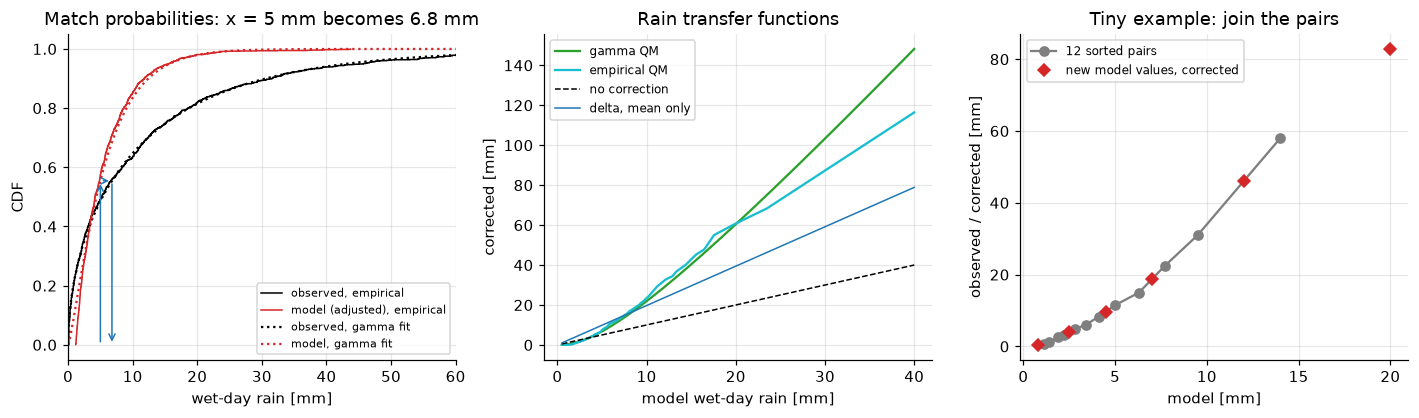

In [8]:
# ---------- empirical quantile mapping ----------
P_KNOTS = np.arange(1, 100) / 100


def qm_empirical(x, obs, mod_base, rain=True):
    if rain:
        qo = np.percentile(obs[obs > 0], 100 * P_KNOTS)
        qm = np.percentile(mod_base[mod_base > 0], 100 * P_KNOTS)
        y = np.interp(x, qm, qo)
        y = np.where(x < qm[0], x * qo[0] / qm[0], y)
        y = np.where(x >= qm[-1], x * qo[-1] / qm[-1], y)
        return np.where(x > 0, y, 0.0)
    qo = np.percentile(obs, 100 * P_KNOTS)
    qm = np.percentile(mod_base, 100 * P_KNOTS)
    y = np.interp(x, qm, qo)
    y = np.where(x < qm[0], x + (qo[0] - qm[0]), y)
    y = np.where(x >= qm[-1], x + (qo[-1] - qm[-1]), y)
    return y


# ---- tiny example: 12 observed and 12 model wet-day values (mm), unsorted
obs12 = np.array([11.5, 0.6, 31.0, 3.1, 8.3, 58.0, 1.2, 22.4, 4.8, 15.0, 2.5, 6.0])
mod12 = np.array([4.1, 1.4, 9.5, 2.2, 6.3, 14.0, 1.1, 5.0, 2.8, 7.7, 1.9, 3.4])
so12, sm12 = np.sort(obs12), np.sort(mod12)
print("sorted obs  :", so12)
print("sorted model:", sm12)

def qm_tiny(x):
    if x < sm12[0]:  return x * so12[0] / sm12[0], "below range: ratio of the smallest pair"
    if x >= sm12[-1]: return x * so12[-1] / sm12[-1], "above range: ratio of the largest pair"
    return float(np.interp(x, sm12, so12)), "interpolate"

for x in (0.8, 2.5, 4.5, 7.0, 12.0, 20.0):
    y, how = qm_tiny(x)
    i = np.searchsorted(sm12, x, side="right")            # number of model values <= x
    p = (i - 1 + (x - sm12[i - 1]) / (sm12[i] - sm12[i - 1])) / 11 if 0 < i < 12 else float("nan")
    print(f"x = {x:5.1f} mm  probability p = {p:6.3f}  corrected = {y:6.2f} mm   ({how})")

# ---- full series: rain (wet days) and temperature
tab = P_KNOTS
q_obs, q_mod = np.percentile(oc[oc > 0], 100 * tab), np.percentile(mc[mc > 0], 100 * tab)
print()
print("rain table: model q(0.50) = %.2f, q(0.99) = %.2f mm ; observed q(0.50) = %.2f, q(0.99) = %.2f mm" % (q_mod[49], q_mod[98], q_obs[49], q_obs[98]))
for tgt in ("mod_val", "mod_fut"):
    xr, xt = adj[tgt], T[tgt]
    out_r = np.sum((xr >= q_mod[-1]) | ((xr > 0) & (xr < q_mod[0])))
    qmT = np.percentile(T["mod_cal"], 100 * tab)
    out_t = np.sum((xt >= qmT[-1]) | (xt < qmT[0]))
    print(f"{tgt}: days outside the calibration table: rain {out_r} of {np.sum(xr > 0)} wet days, temperature {out_t} of {len(xt)}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.9))
# (a) fitted CDFs and the mapping arrows
xs = np.linspace(0, 80, 400)
for arr, c, lab in ((oc[oc > 0], "k", "observed"), (mc[mc > 0], "tab:red", "model (adjusted)")):
    s_ = np.sort(arr); ax[0].step(s_, np.arange(1, len(s_) + 1) / (len(s_) + 1), c=c, lw=1, where="post", label=lab + ", empirical")
ax[0].plot(xs, stats.gamma.cdf(xs, ko, scale=to), "k:", label="observed, gamma fit")
ax[0].plot(xs, stats.gamma.cdf(xs, km, scale=tm), ":", c="tab:red", label="model, gamma fit")
ax[0].annotate("", xy=(x0, p0), xytext=(x0, 0), arrowprops=dict(arrowstyle="->", color="tab:blue"))          # up to the model CDF
ax[0].annotate("", xy=(y0, p0), xytext=(x0, p0), arrowprops=dict(arrowstyle="->", color="tab:blue"))          # across to the observed CDF
ax[0].annotate("", xy=(y0, 0), xytext=(y0, p0), arrowprops=dict(arrowstyle="->", color="tab:blue"))           # down to the corrected value
ax[0].set(xlim=(0, 60), xlabel="wet-day rain [mm]", ylabel="CDF", title="Match probabilities: x = 5 mm becomes %.1f mm" % y0); ax[0].legend(fontsize=7, loc="lower right")
# (b) transfer functions
xg = np.linspace(0.5, 40, 300)
ax[1].plot(xg, qm_gamma(xg, oc, mc), "tab:green", label="gamma QM")
ax[1].plot(xg, qm_empirical(xg, oc, mc), "tab:cyan", label="empirical QM")
ax[1].plot(xg, xg, "k--", lw=1, label="no correction")
ax[1].plot(xg, xg * oc[oc > 0].mean() / mc[mc > 0].mean(), "tab:blue", lw=1, label="delta, mean only")
ax[1].set(xlabel="model wet-day rain [mm]", ylabel="corrected [mm]", title="Rain transfer functions"); ax[1].legend(fontsize=8)
# (c) the tiny example
ax[2].plot(sm12, so12, "o-", c="tab:gray", label="12 sorted pairs")
xn = np.array([0.8, 2.5, 4.5, 7.0, 12.0, 20.0]); yn = [qm_tiny(v)[0] for v in xn]
ax[2].plot(xn, yn, "D", c="tab:red", label="new model values, corrected")
ax[2].set(xlabel="model [mm]", ylabel="observed / corrected [mm]", title="Tiny example: join the pairs"); ax[2].legend(fontsize=8)
fig.tight_layout();

Panel (a) is the whole idea in one picture: start at $x=5$ mm on the model curve, go across to its probability, then across to the observed curve and read the value. Panel (b) shows that the two quantile mappings are curved (they correct light and heavy rain by different factors, which the single ratio of the delta method cannot), and that gamma and empirical mapping agree closely in the body. Panel (c) is the 12-value example: the new value of 20 mm lies above the largest model value (14 mm), so it takes the ratio of the largest pair (58/14), the extrapolation rule above. The rule is not a detail: in the future run 473 of the 2440 temperature days (19 %) and 67 of the 1358 wet days lie outside the calibration table, against 69 and 29 in the validation run, because a warmer, wetter climate pushes values beyond anything the calibration period contained.

# 6) Quantile delta mapping and the climate-change signal

**The problem.** Quantile mapping is fitted on the calibration period only. When the model's future distribution $F_f$ differs from $F_h$, the future values sit at *different* probabilities than they did in the past and the map treats them as if the model were biased in a new way. Part of the model's signal is then reinterpreted as bias and removed or amplified.

**How plain quantile mapping can distort the change.** Take temperature with normal distributions and a model that warms by a pure shift $\Delta$, $x_f=x_h+\Delta$. Using the straight-line map of Section 5.1,

$$\hat y_f-\hat y_h=\frac{\sigma_o}{\sigma_m}\,(x_f-x_h)=\frac{\sigma_o}{\sigma_m}\,\Delta .$$

The corrected warming is the model's warming **times the ratio of the standard deviations**. Our model is too variable ($\sigma_m=3.0$ against $\sigma_o=2.2$ &deg;C), so a 3 K model warming becomes about 2.2 K. For rain, work with logarithms. Let $g_o(\tau)=\ln q_o(\tau)$ and $g_m(\tau)=\ln q_m(\tau)$ be the log-quantile functions. The map is $\ln\hat y=g_o\big(g_m^{-1}(\ln x)\big)$, so if the model scales a quantile by a factor $c$ (adding $\ln c$ to $\ln x$), a first-order expansion gives

$$\ln\hat y_f-\ln\hat y_h\approx\frac{g_o'(\tau)}{g_m'(\tau)}\,\ln c\quad\Longrightarrow\quad \text{corrected change}\approx c^{\,g_o'(\tau)/g_m'(\tau)} .$$

The model's relative change $c$ is raised to the ratio of the *slopes of the log-quantile curves*. If the observed tail is heavier than the model tail the change is amplified, if lighter it is damped, and only if the two curves have the same shape (for example equal gamma shapes) is it preserved.

**Quantile delta mapping.** The remedy is to separate the signal from the correction. For a future model value $x$:

1. find its probability **within the future series**, $\tau=F_f(x)$ (its rank among the future values),
2. compute the model's own change at that probability, the **delta** $\Delta(\tau)=\dfrac{x}{F_h^{-1}(\tau)}$ for rain, or $\Delta(\tau)=x-F_h^{-1}(\tau)$ for temperature,
3. take the **observed** quantile at the same probability and apply the delta to it:

$$\boxed{\;\hat y=F_o^{-1}(\tau)\,\frac{x}{F_h^{-1}(\tau)}\quad\text{(rain)},\qquad \hat y=F_o^{-1}(\tau)+\big[x-F_h^{-1}(\tau)\big]\quad\text{(temperature)}\;}$$

**Why it preserves the change.** The $\tau$-quantile of the future model series is $Q_f(\tau)=F_f^{-1}(\tau)$, and a value $x=Q_f(\tau)$ is mapped to $\hat y=Q_o(\tau)\,Q_f(\tau)/Q_h(\tau)$. If the map is increasing, the $\tau$-quantile of the corrected future series is therefore exactly this value, and dividing by the observed quantile,

$$\frac{Q_{\hat y}(\tau)}{Q_o(\tau)}=\frac{Q_f(\tau)}{Q_h(\tau)}\qquad\text{for every }\tau .$$

*The relative change of each quantile of the corrected series equals the model's projected relative change.* In the additive form the same steps give $Q_{\hat y}(\tau)-Q_o(\tau)=Q_f(\tau)-Q_h(\tau)$. As a check: if there is no climate change, $F_f=F_h$, $\Delta=1$ and $\hat y=Q_o(\tau)=F_o^{-1}(F_h(x))$, which is ordinary quantile mapping. The map is increasing whenever $Q_o(\tau)\,\Delta(\tau)$ increases with $\tau$, which holds in all practical cases; if it fails the corrected series can swap the order of two days.

What QDM does **not** do is judge the model's change. It trusts it. This is the assumption of Section 1 in its sharpest form: the model's *relative* change in each quantile is credible. In our laboratory it is, by construction.

RAIN: ratio (future quantile)/(baseline quantile)
                  model change  QM gamma  QM empirical    QDM  truth
wet-day quantile                                                    
0.50                     1.028     0.981         1.040  1.024  1.115
0.75                     1.175     1.217         1.289  1.175  1.238
0.90                     1.395     1.458         1.517  1.391  1.312
0.95                     1.413     1.516         1.439  1.412  1.332
0.99                     1.550     1.928         1.550  1.550  1.529

TEMPERATURE: warming (future quantile) - (baseline quantile), K
          model change  QM normal  QM empirical   QDM  truth
quantile                                                    
0.10              2.26       1.65          1.68  2.26    2.3
0.50              3.23       2.34          2.24  3.22    3.1
0.90              4.15       3.06          3.51  4.16    3.9
0.95              4.21       3.00          3.75  4.20    3.8
0.99              4.88       3.47   

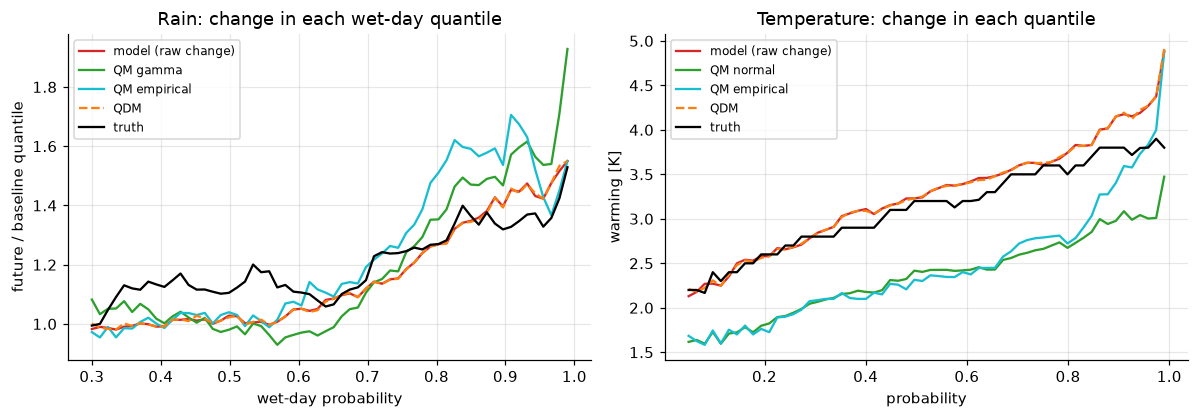

In [9]:
# ---------- quantile delta mapping (empirical) ----------
def qdm(x, obs, mod_base, rain=True):
    if rain:
        wet = x > 0
        xs = np.sort(x[wet])
        tau = np.searchsorted(xs, x[wet], side="right") / (len(xs) + 1)
        qo = np.percentile(obs[obs > 0], 100 * tau)
        qm = np.percentile(mod_base[mod_base > 0], 100 * tau)
        y = np.zeros(len(x))
        y[wet] = qo * x[wet] / qm
        return y
    xs = np.sort(x)
    tau = np.searchsorted(xs, x, side="right") / (len(xs) + 1)
    return np.percentile(obs, 100 * tau) + (x - np.percentile(mod_base, 100 * tau))


pr_ = np.array([0.5, 0.75, 0.9, 0.95, 0.99])                   # probability levels for the signal check
wq = lambda a, p: np.percentile(a[a > 0], 100 * p)            # wet-day quantile

xf = adj["mod_fut"]
y_qmg, y_qme, y_qdm = qm_gamma(xf, oc, mc), qm_empirical(xf, oc, mc), qdm(xf, oc, mc)
tab_r = pd.DataFrame({
    "model change": wq(xf, pr_) / wq(mc, pr_),
    "QM gamma": wq(y_qmg, pr_) / wq(oc, pr_),
    "QM empirical": wq(y_qme, pr_) / wq(oc, pr_),
    "QDM": wq(y_qdm, pr_) / wq(oc, pr_),
    "truth": wq(P["tru_fut"], pr_) / wq(oc, pr_)}, index=pr_)
tab_r.index.name = "wet-day quantile"
print("RAIN: ratio (future quantile)/(baseline quantile)"); print(tab_r.round(3).to_string())

pt = np.array([0.1, 0.5, 0.9, 0.95, 0.99])
xt = T["mod_fut"]
t_qmn, t_qme, t_qdm = qm_normal(xt, T["obs_cal"], T["mod_cal"]), qm_empirical(xt, T["obs_cal"], T["mod_cal"], rain=False), qdm(xt, T["obs_cal"], T["mod_cal"], rain=False)
pc_ = lambda a, p: np.percentile(a, 100 * p)
tab_t = pd.DataFrame({
    "model change": pc_(xt, pt) - pc_(T["mod_cal"], pt),
    "QM normal": pc_(t_qmn, pt) - pc_(T["obs_cal"], pt),
    "QM empirical": pc_(t_qme, pt) - pc_(T["obs_cal"], pt),
    "QDM": pc_(t_qdm, pt) - pc_(T["obs_cal"], pt),
    "truth": pc_(T["tru_fut"], pt) - pc_(T["obs_cal"], pt)}, index=pt)
tab_t.index.name = "quantile"
print("\nTEMPERATURE: warming (future quantile) - (baseline quantile), K"); print(tab_t.round(2).to_string())
print("\nsigma_o/sigma_m = %.2f: QM turns a model warming of %.2f K at the median into %.2f K (truth %.2f K)" %
      (T["obs_cal"].std(ddof=1) / T["mod_cal"].std(ddof=1), tab_t.loc[0.5, "model change"], tab_t.loc[0.5, "QM normal"], tab_t.loc[0.5, "truth"]))

pg = np.linspace(0.30, 0.99, 60)       # wet-day probabilities; the lowest wet-day quantiles sit at the threshold and are not informative
pg_t = np.linspace(0.05, 0.99, 60)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
ax[0].plot(pg, wq(xf, pg) / wq(mc, pg), "tab:red", label="model (raw change)")
ax[0].plot(pg, wq(y_qmg, pg) / wq(oc, pg), "tab:green", label="QM gamma")
ax[0].plot(pg, wq(y_qme, pg) / wq(oc, pg), "tab:cyan", label="QM empirical")
ax[0].plot(pg, wq(y_qdm, pg) / wq(oc, pg), "tab:orange", ls="--", label="QDM")
ax[0].plot(pg, wq(P["tru_fut"], pg) / wq(oc, pg), "k", label="truth")
ax[0].set(xlabel="wet-day probability", ylabel="future / baseline quantile", title="Rain: change in each wet-day quantile"); ax[0].legend(fontsize=8)
ax[1].plot(pg_t, pc_(xt, pg_t) - pc_(T["mod_cal"], pg_t), "tab:red", label="model (raw change)")
ax[1].plot(pg_t, pc_(t_qmn, pg_t) - pc_(T["obs_cal"], pg_t), "tab:green", label="QM normal")
ax[1].plot(pg_t, pc_(t_qme, pg_t) - pc_(T["obs_cal"], pg_t), "tab:cyan", label="QM empirical")
ax[1].plot(pg_t, pc_(t_qdm, pg_t) - pc_(T["obs_cal"], pg_t), "tab:orange", ls="--", label="QDM")
ax[1].plot(pg_t, pc_(T["tru_fut"], pg_t) - pc_(T["obs_cal"], pg_t), "k", label="truth")
ax[1].set(xlabel="probability", ylabel="warming [K]", title="Temperature: change in each quantile"); ax[1].legend(fontsize=8)
fig.tight_layout();

Read the two tables. The QDM column equals the model-change column in every row (to within 0.004 for rain and 0.03 K for temperature, the effect of rounding and of interpolation in the percentile): this is the property derived above, and it holds for any model signal, not only for this one. Plain quantile mapping departs from it. For temperature it turns the model's median warming of 3.23 K into 2.34 K, almost exactly the factor $\sigma_o/\sigma_m=0.72$ of the derivation ($0.72\times3.23=2.33$). For rain, gamma quantile mapping turns the model's change of 1.55 at the 99th wet-day percentile into 1.93, because the fitted observed tail is steeper than the model's tail (the exponent $g_o'/g_m'$ exceeds 1), and empirical mapping inflates the changes at 0.75 and 0.9 (1.29 and 1.52 against 1.18 and 1.40). The empirical map matches the model at 0.99 only because above its table it falls back on the constant-ratio rule of Section 5.3, which keeps the ratio by construction. The truth differs from the model's change at some levels (for example at the median for rain) because of sampling noise in 20 seasons and because, in the model, the wet-day frequency also changes; QDM faithfully passes on whatever the model says. Sheet `QDM` of the workbook has the same two tables with live formulas, and its day-by-day columns show $\tau$, the two quantiles, $\Delta$ and $\hat y$ for every day.

# 7) Comparing the methods

| Method | What it corrects | Main assumptions | Strengths | Failure modes |
|:--|:--|:--|:--|:--|
| **Occurrence adjustment** | Wet-day frequency | The model's wet days above a threshold match the observed ones; the threshold is stable in time | Removes drizzle; needed before any intensity correction | A single threshold for all months or regions; changes in wet-day frequency in the future are left to the model |
| **Delta, mean only** (additive for T, ratio for rain) | Mean | Bias is a constant shift (T) or constant fraction (rain) | Very simple; transparent; few parameters; robust with short records | Spread and tail untouched; ratio unstable if the model mean is near zero |
| **Delta, mean and spread** | Mean and standard deviation | As above, plus a constant ratio of spreads | Fixes the first two moments cheaply | Shape and tail untouched; **negative rain** for light wet days; wet-day fraction not repaired |
| **Quantile mapping, parametric** (gamma, normal) | Whole distribution within the family | The family fits both observed and model distributions, in the tail too; the bias is stationary | Smooth; few parameters; can extrapolate beyond the sample | Wrong family means wrong extremes; moment fits are sensitive to outliers; can **distort the climate-change signal** |
| **Quantile mapping, empirical** | Whole distribution, no family | The bias is stationary; enough data for the quantiles | No distributional assumption; keeps the shape of the data | Tail noisy and capped by the sample; needs an extrapolation rule; can **distort the climate-change signal** |
| **Quantile delta mapping** | Whole distribution **and** keeps the model's relative change in each quantile | The model's *relative* change is credible; the bias is stationary | Preserves the signal exactly; reduces to QM with no change | Inherits every model error in the signal; can produce unrealistic extremes if the model's change is large; ratios unstable near zero |

None of them corrects timing, spatial structure, or the relation between variables. Which one to use depends on the purpose. For a flood design the **extremes** matter most and the tail of a method is the thing to inspect; for drought analysis the **wet-day frequency and the dry spells** matter, so the occurrence step is important; for a water balance the mean may be enough. The choice is judged with held-out data, as in the next section.

# 8) Validation: split-sample and metrics

Because every method is fitted to match the calibration data, a good calibration fit says nothing about skill. The standard test is a **split-sample** one: fit on one part of the record and score on another part that was kept out. Our laboratory gives two held-out tests.

- **Validation** (`mod_val` against `obs_val`): twenty other seasons of the *same* climate. It checks that the correction is not tuned to the sampling noise of the calibration seasons.
- **Future** (`mod_fut` against the truth `tru_fut`): a *different* climate, the test that matters for projection. It is available only in a laboratory (a pseudo-reality). With real data one tests on a contrasting period (calibrate on the dry years and test on the wet years), and checks the future by comparing with other model or regional-climate-model output.

**Metrics.** A free-running model is not synchronised with the weather, so a day-by-day error is meaningless; we compare distributions. With $\hat y$ the corrected series and $y_{\rm ref}$ the reference (observed or truth):

- **bias** of the mean, $\overline{\hat y}-\overline{y_{\rm ref}}$;
- **wet-day fraction** (rain) and **95th percentile of wet-day rain** (an index of heavy rain), or the standard deviation and the 95th percentile (temperature);
- **KS distance**, $D=\max_g |F_{\hat y}(g)-F_{\rm ref}(g)|$, the largest gap between the two empirical CDFs, evaluated here on a fixed grid of values $g$ (an approximation to the exact statistic; sheet `Eval_calc` uses the same grid);
- **quantile RMSE**, $\sqrt{\tfrac1{20}\sum_j\big(Q_{\hat y}(p_j)-Q_{\rm ref}(p_j)\big)^2}$ over 20 probability levels ($0.05,0.10,\dots,0.95,0.99$): the typical error in the quantiles, in the units of the variable.

In [10]:
# ---------- metrics ----------
QLEV = np.array(list(np.arange(0.05, 0.96, 0.05)) + [0.99])
GRID_P = np.array([0, 0.1, 0.25, 0.5, 1, 2, 3, 5, 7.5, 10, 15, 20, 30, 40, 50, 60, 80, 100, 130, 160.0])
GRID_T = np.arange(15, 46, 1.0)


def ecdf_at(x, grid):
    xs = np.sort(x)
    return np.searchsorted(xs, grid, side="right") / len(xs)


def ks_grid(a, b, grid):
    return np.max(np.abs(ecdf_at(a, grid) - ecdf_at(b, grid)))


def qrmse(a, ref):
    return np.sqrt(np.mean((np.percentile(a, 100 * QLEV) - np.percentile(ref, 100 * QLEV)) ** 2))


def wet_p95(x):
    w = x[x > 0]
    return np.percentile(w, 95) if len(w) else np.nan


def corrections(var, target):
    """All corrected versions of one model series: dict method -> array."""
    if var == "rain":
        x = adj[target]
        return {"Raw model": P[target], "Occurrence only": x,
                "Delta (mean)": delta_rain(x, oc, mc, True), "Delta (mean+spread)": delta_rain(x, oc, mc),
                "QM gamma": qm_gamma(x, oc, mc), "QM empirical": qm_empirical(x, oc, mc), "QDM": qdm(x, oc, mc)}
    to_, tm_ = T["obs_cal"], T["mod_cal"]
    x = T[target]
    return {"Raw model": x, "Delta (shift)": delta_temp(x, to_, tm_), "Delta (shift+spread)": delta_temp(x, to_, tm_, False),
            "QM normal": qm_normal(x, to_, tm_), "QM empirical": qm_empirical(x, to_, tm_, False), "QDM": qdm(x, to_, tm_, False)}


def score(series, ref, var):
    rows = {}
    for name, y in series.items():
        if var == "rain":
            rows[name] = {"mean bias": y.mean() - ref.mean(), "wet-day fraction": np.mean(y > 0), "P95 wet-day bias": wet_p95(y) - wet_p95(ref),
                          "KS": ks_grid(y, ref, GRID_P), "quantile RMSE": qrmse(y, ref)}
        else:
            rows[name] = {"mean bias": y.mean() - ref.mean(), "SD bias": y.std(ddof=1) - ref.std(ddof=1), "P95 bias": np.percentile(y, 95) - np.percentile(ref, 95),
                          "KS": ks_grid(y, ref, GRID_T), "quantile RMSE": qrmse(y, ref)}
    return pd.DataFrame(rows).T


C = {("rain", "val"): corrections("rain", "mod_val"), ("rain", "fut"): corrections("rain", "mod_fut"),
     ("temp", "val"): corrections("temp", "mod_val"), ("temp", "fut"): corrections("temp", "mod_fut")}
REF = {("rain", "val"): P["obs_val"], ("rain", "fut"): P["tru_fut"], ("temp", "val"): T["obs_val"], ("temp", "fut"): T["tru_fut"]}
S = {k: score(C[k], REF[k], k[0]) for k in C}

print(f"reference wet-day fraction: validation {np.mean(P['obs_val'] > 0):.3f}, truth {np.mean(P['tru_fut'] > 0):.3f}")
print("\nRAIN, validation (held-out historical seasons)"); print(S[("rain", "val")].round(3).to_string())
print("\nRAIN, future against the synthetic truth"); print(S[("rain", "fut")].round(3).to_string())

reference wet-day fraction: validation 0.564, truth 0.558

RAIN, validation (held-out historical seasons)
                     mean bias  wet-day fraction  P95 wet-day bias     KS  quantile RMSE
Raw model               -2.940             0.919           -28.330  0.355         10.874
Occurrence only         -3.099             0.542           -25.384  0.107         10.868
Delta (mean)            -0.045             0.542            -9.861  0.152          5.356
Delta (mean+spread)      0.141             0.422             7.638  0.142          1.260
QM gamma                -0.138             0.542             2.767  0.031          0.801
QM empirical             0.046             0.542             5.075  0.032          0.675
QDM                      0.010             0.542             5.037  0.030          0.576

RAIN, future against the synthetic truth
                     mean bias  wet-day fraction  P95 wet-day bias     KS  quantile RMSE
Raw model               -4.122             0.923   

In [11]:
print("TEMPERATURE, validation (held-out historical seasons)"); print(S[("temp", "val")].round(3).to_string())
print("\nTEMPERATURE, future against the synthetic truth"); print(S[("temp", "fut")].round(3).to_string())

TEMPERATURE, validation (held-out historical seasons)
                      mean bias  SD bias  P95 bias     KS  quantile RMSE
Raw model                -3.056    0.743    -1.730  0.457          3.073
Delta (shift)             0.057    0.743     1.383  0.085          0.790
Delta (shift+spread)      0.057   -0.098    -0.026  0.025          0.100
QM normal                 0.001   -0.098    -0.082  0.019          0.090
QM empirical             -0.001   -0.080     0.051  0.023          0.079
QDM                       0.055   -0.067     0.090  0.033          0.097

TEMPERATURE, future against the synthetic truth
                      mean bias  SD bias  P95 bias     KS  quantile RMSE
Raw model                -2.962    0.981    -1.390  0.371          3.011
Delta (shift)             0.150    0.981     1.723  0.094          1.036
Delta (shift+spread)      0.150   -0.023     0.111  0.029          0.199
QM normal                -0.757   -0.023    -0.797  0.113          0.758
QM empirical         

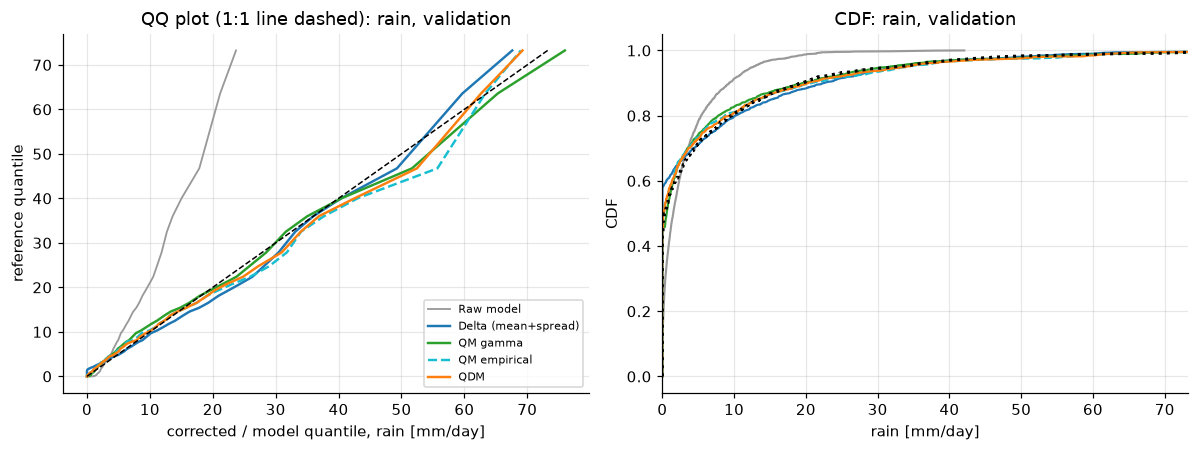

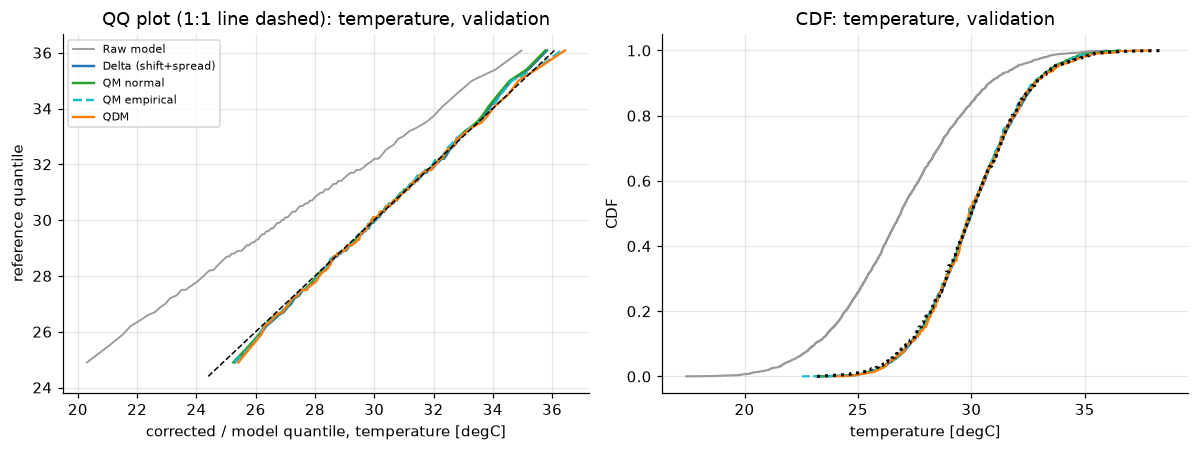

In [12]:
COL = {"Raw model": "0.6", "Delta (mean+spread)": "tab:blue", "Delta (shift+spread)": "tab:blue", "QM gamma": "tab:green", "QM normal": "tab:green",
       "QM empirical": "tab:cyan", "QDM": "tab:orange"}
LS = {"QM empirical": "--", "QDM": "-"}
pq = np.concatenate([np.arange(0.01, 0.99, 0.01), [0.99, 0.995]])


def qq_cdf(var, test, title):
    ref = REF[(var, test)]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    for name, y in C[(var, test)].items():
        if name not in COL:
            continue
        ax[0].plot(np.percentile(y, 100 * pq), np.percentile(ref, 100 * pq), c=COL[name], ls=LS.get(name, "-"), lw=1.6 if name != "Raw model" else 1.2, label=name)
        xs = np.sort(y)
        ax[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), c=COL[name], ls=LS.get(name, "-"), lw=1.4, label=name)
    xs = np.sort(ref); ax[1].plot(xs, np.arange(1, len(xs) + 1) / len(xs), "k:", lw=2, label="reference")
    lo, hi = np.percentile(ref, 0.5), np.percentile(ref, 99.5)
    ax[0].plot([lo, hi], [lo, hi], "k--", lw=1)
    unit = "rain [mm/day]" if var == "rain" else "temperature [degC]"
    ax[0].set(xlabel="corrected / model quantile, " + unit, ylabel="reference quantile", title="QQ plot (1:1 line dashed): " + title)
    ax[1].set(xlabel=unit, ylabel="CDF", title="CDF: " + title)
    if var == "rain":
        ax[1].set_xlim(0, np.percentile(ref, 99.5))
    ax[0].legend(fontsize=7); fig.tight_layout()


qq_cdf("rain", "val", "rain, validation")
qq_cdf("temp", "val", "temperature, validation")

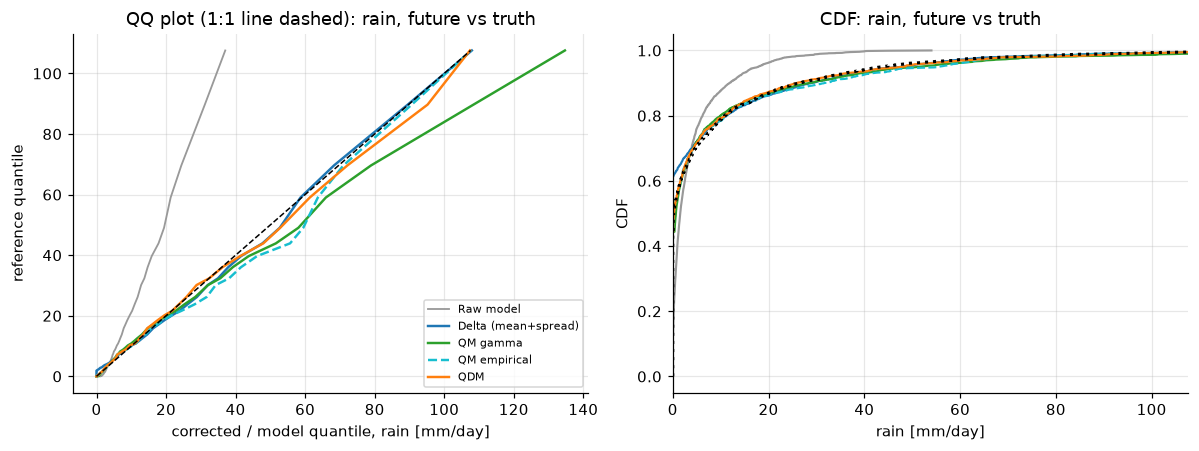

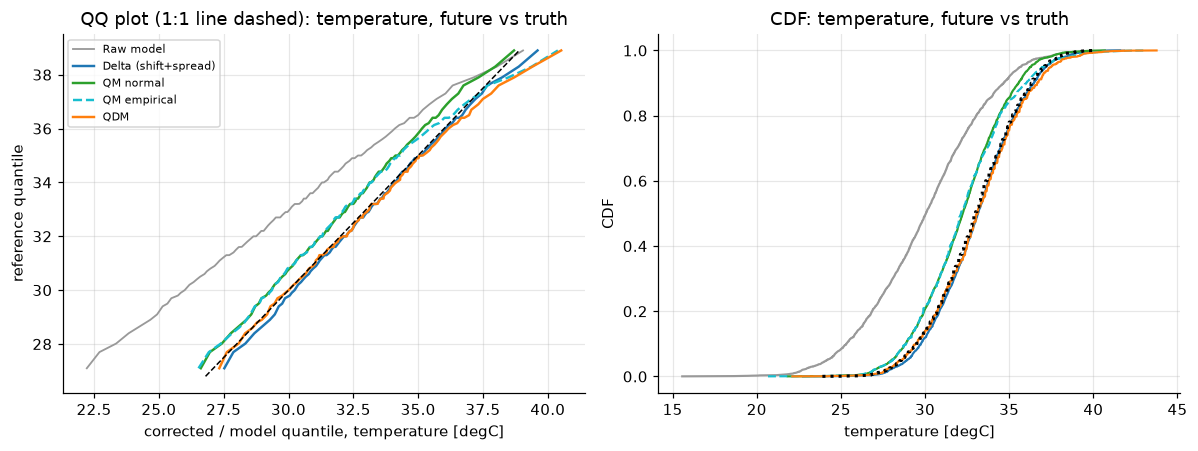

In [13]:
qq_cdf("rain", "fut", "rain, future vs truth")
qq_cdf("temp", "fut", "temperature, future vs truth")

In [14]:
# How much of the ranking is sampling noise? Repeat the whole experiment with 20 different sets of random numbers.
def one_trial(seed):
    uP_, uT_ = make_uniforms(seed)
    P_, T_ = make_series(uP_, uT_)
    o_, thr_ = P_["obs_cal"], occ_threshold(P_["obs_cal"], P_["mod_cal"])
    m_ = occ_adjust(P_["mod_cal"], thr_)
    x_ = occ_adjust(P_["mod_fut"], thr_)
    rain = {"Delta (mean)": delta_rain(x_, o_, m_, True), "Delta (mean+spread)": delta_rain(x_, o_, m_), "QM gamma": qm_gamma(x_, o_, m_),
            "QM empirical": qm_empirical(x_, o_, m_), "QDM": qdm(x_, o_, m_)}
    tt_, tm_, xt_ = T_["obs_cal"], T_["mod_cal"], T_["mod_fut"]
    temp = {"Delta (shift+spread)": delta_temp(xt_, tt_, tm_, False), "QM normal": qm_normal(xt_, tt_, tm_),
            "QM empirical": qm_empirical(xt_, tt_, tm_, False), "QDM": qdm(xt_, tt_, tm_, False)}
    r = {("rain", k): (qrmse(v, P_["tru_fut"]), np.mean(v > 0)) for k, v in rain.items()}
    r.update({("temp", k): (qrmse(v, T_["tru_fut"]), np.nan) for k, v in temp.items()})
    return r


trials = [one_trial(s) for s in range(100, 120)]
rows = {}
for key in trials[0]:
    a = np.array([t[key] for t in trials])
    rows[key] = {"quantile RMSE, mean": a[:, 0].mean(), "quantile RMSE, sd": a[:, 0].std(ddof=1), "wet-day fraction, mean": a[:, 1].mean()}
res = pd.DataFrame(rows).T
res.index.names = ["variable", "method"]
print("Future versus truth, 20 repeated experiments (truth wet-day fraction is 0.55)")
res.round(3)

Future versus truth, 20 repeated experiments (truth wet-day fraction is 0.55)


quantile RMSE, mean  quantile RMSE, sd  \
variable method                                                         
rain     Delta (mean)                        6.161              1.645   
         Delta (mean+spread)                 2.694              1.631   
         QM gamma                            5.478              3.507   
         QM empirical                        3.271              2.236   
         QDM                                 2.669              1.581   
temp     Delta (shift+spread)                0.259              0.110   
         QM normal                           0.859              0.198   
         QM empirical                        0.802              0.196   
         QDM                                 0.257              0.084   

                               wet-day fraction, mean  
variable method                                        
rain     Delta (mean)                           0.564  
         Delta (mean+spread)                    0.407  
         QM gamma                               0.564  
         QM empirical                           0.564  
         QDM                                    0.564  
temp     Delta (shift+spread)                     NaN  
         QM normal                                NaN  
         QM empirical                             NaN  
         QDM                                      NaN

**Reading the tables and figures** (numbers are from this run; the code is deterministic, so yours should agree).

- **Occurrence adjustment alone** lowers the wet-day fraction from 0.92 to 0.54 and the KS distance from 0.36 to 0.11, but the wet-day rain is still far too light: the 95th percentile is about 25 mm short and the quantile RMSE is 10.9 mm.
- **Validation (same climate).** The three quantile-based methods reach a quantile RMSE of 0.6&ndash;0.8 mm and a KS distance of about 0.03. The mean-only delta leaves the tail short (P95 9.9 mm low); the mean-and-spread delta overshoots it and its wet-day fraction drops to 0.42 because the floor at zero removes 293 negative values. For temperature the shift alone fixes the mean but not the spread, while the spread-corrected delta, QM and QDM all give about 0.1 K and cannot be told apart.
- **Future against the truth.** The quantile mappings that reproduce the past misplace the *change*. For temperature the quantile RMSE of QM normal rises from 0.09 K (validation) to 0.76 K, and its mean bias of $-0.76$ K is the damped warming of Section 6; QDM stays at 0.30 K with no mean bias. For rain, gamma QM overshoots the heavy rain (P95 8.3 mm high, quantile RMSE 4.6 mm), empirical QM does better (2.9 mm) and QDM best (1.6 mm). For near-normal temperature the mean-and-spread delta (0.20 K) is as good as QDM within noise; for bounded and skewed rain it is not, because of the lost wet days.

**How much is noise?** Two realisations of the *same* climate differ in their tails: here the validation 95th percentile of wet-day rain is 41 mm against 45 mm in the calibration seasons, which is why even the best methods show a P95 error of a few millimetres in the validation table. The repeated experiment above, with 20 new sets of random numbers, gives the averages: for rain QDM and the mean-and-spread delta have the same mean quantile RMSE (2.7 mm) but the delta has only 41 % wet days against about 55 %; empirical QM follows with 3.3 mm, gamma QM with 5.5 mm (and a large spread between experiments) and the mean-only delta with 6.2 mm. For temperature QDM and the spread-corrected delta are tied (0.26 K) and QM is about three times worse (0.8&ndash;0.9 K). No single metric ranks the methods; the wet-day fraction, a tail index and a whole-distribution measure are all needed.

One last caution: this laboratory gives the model a signal that is exactly right. A well-behaved correction says nothing about how good the model's signal is in the real world.

# 9) The companion spreadsheet

`data/downscaling/lec18/lec18_worked_examples.xlsx` repeats the calculations with live formulas (blue font = inputs, black = formulas, green = links to another sheet, yellow fill = key results), so each step can be followed cell by cell. The workbook has the **same random numbers** as `lec18_uniform_numbers.csv`, so its results equal those of this notebook.

| Sheet | Content | Section |
|:--|:--|:--|
| `README`, `Params`, `Data` | purpose and colour code; the parameters of the synthetic world (change the model bias and everything recalculates); the fixed random numbers and the six series | 2 |
| `Occurrence` | wet-day threshold with `PERCENTILE.INC`, drizzle table and chart, adjusted series | 3 |
| `Delta` | mean-only and mean-and-spread scaling for rain and temperature, count of negative values, ratio-near-zero example | 4 |
| `QM_tiny` | the 12-value example, step by step, with a chart | 5.3 |
| `QM_gamma` | moment fit, `GAMMA.DIST` then `GAMMA.INV` (rain) and `NORM.DIST`/`NORM.INV` (temperature), day by day | 5.2 |
| `QM_empirical` | table of 99 quantiles, `MATCH`/`INDEX` interpolation, constant extrapolation, count of days outside the table | 5.3 |
| `QDM` | $\tau$, $F_o^{-1}(\tau)$, $F_h^{-1}(\tau)$, $\Delta$, $\hat y$ for every day; the signal-preservation tables | 6 |
| `Evaluation`, `Eval_calc` | the metrics of Section 8 for validation and future, with the ECDF grid and quantile tables that feed them | 8 |

The cell below reads the stored series, checks that this notebook generates exactly the same numbers, and prints some cells to look up in the workbook.

In [15]:
try:
    saved = pd.read_csv("data/downscaling/lec18/lec18_synthetic_series.csv")
except Exception:
    saved = pd.read_csv("https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/downscaling/lec18/lec18_synthetic_series.csv")
d_r = max(np.abs(saved["rain_" + k].to_numpy() - P[k]).max() for k in COLS)
d_t = max(np.abs(saved["temp_" + k].to_numpy() - T[k]).max() for k in COLS)
print(f"largest difference between the stored series and this notebook: rain {d_r:.1e} mm, temperature {d_t:.1e} degC")

print("\nNumbers to find in the workbook")
print(f"  Occurrence!B8   wet-day threshold                 : {thr:.4f} mm/day")
print(f"  QM_gamma!B6:C7  gamma shape/scale, obs and model   : {ko:.4f}, {to:.4f} | {km:.4f}, {tm:.4f}")
print(f"  QM_tiny!D20:D25 corrected values                    : {[round(float(qm_tiny(v)[0]), 2) for v in (0.8, 2.5, 4.5, 7.0, 12.0, 20.0)]}")
print(f"  Evaluation      future rain, QDM quantile RMSE      : {S[('rain', 'fut')].loc['QDM', 'quantile RMSE']:.3f} mm")
print(f"  Evaluation      future temperature, QM normal RMSE  : {S[('temp', 'fut')].loc['QM normal', 'quantile RMSE']:.3f} degC")

largest difference between the stored series and this notebook: rain 0.0e+00 mm, temperature 0.0e+00 degC

Numbers to find in the workbook
  Occurrence!B8   wet-day threshold                 : 1.2072 mm/day
  QM_gamma!B6:C7  gamma shape/scale, obs and model   : 0.5189, 21.9328 | 1.3143, 4.3906
  QM_tiny!D20:D25 corrected values                    : [0.44, 3.95, 9.72, 18.7, 46.0, 82.86]
  Evaluation      future rain, QDM quantile RMSE      : 1.576 mm
  Evaluation      future temperature, QM normal RMSE  : 0.758 degC


# Summary

- Climate models have **systematic biases** in the distribution of daily values. Bias correction fits a mapping on a calibration period and applies it to the future, under the assumption that the bias is **stationary**. It does not repair timing, wrong processes, spatial scale, relations between variables or a wrong projected change, and it must be **validated on held-out data**.
- **Occurrence adjustment** sets the model threshold at the quantile $t=F_m^{-1}(1-f_o)$, so the model has the observed wet-day fraction; it removes drizzle and is done first.
- The **delta method** scales the model by $m_o/m_h$ (multiplicative, rain: bounded at zero, bias proportional) or shifts it by $m_o-m_h$ (additive, temperature), optionally also by the spread ratio. It corrects only moments, and ratios near zero or large spread factors give nonsense.
- **Quantile mapping** is $\hat y=F_o^{-1}(F_m(x))$: equate non-exceedance probabilities. With gamma (rain) or normal (temperature) fits it is parametric; with quantile tables, interpolation and a constant correction outside the range it is empirical.
- Plain quantile mapping can **distort the climate-change signal**: for normal distributions it multiplies the warming by $\sigma_o/\sigma_m$. **Quantile delta mapping** takes the observed quantile at the future probability and applies the model's own delta, so the corrected series has the model's relative (rain) or absolute (temperature) change in **every quantile**. It trusts the model's change.
- Judge methods with distribution metrics (bias, wet-day fraction, P95, KS, quantile RMSE) on a validation period and on a different climate, never on the calibration fit alone.

```{admonition} The idea to remember
Bias correction decides *where* the model's values sit. Whether the model's **change** is believable is a separate question that no correction answers.
```

# Try it yourself

- In the workbook (`Params`), make the model temperature bias $-6$ &deg;C instead of $-3$ &deg;C and watch which methods in `Evaluation` break first. Then set the model's standard deviation equal to the observed one and check that QM and QDM now give the same warming.
- Change the occurrence threshold in the notebook (replace `thr` by 0.1 mm and by 3 mm) and see what happens to the wet-day fraction, the heavy-rain quantile bias and the quantile RMSE.
- Shorten the calibration period to 5 seasons (use only the first 610 days of `obs_cal` and `mod_cal`) and compare the empirical and gamma quantile mapping. Which one degrades more in the tail, and why?
- Use a smaller number of table quantiles in `qm_empirical` (for example every 0.05) and look at the extrapolated days in the future.
- *Optional:* replace the synthetic series by an IMD gridded rainfall series for a cell near your catchment and a NEX-GDDP-CMIP6 series for the same cell, and repeat Sections 3 to 8 month by month.

# Check your understanding

1. A model has 85 % wet days and the gauge 45 %. A colleague applies a multiplicative delta (ratio of mean daily rain) and says the bias is fixed. What is still wrong, and which step should come first?
2. Starting from $F_o(\hat y)=F_m(x)$, show that quantile mapping with two normal distributions is a straight line, and that for two gamma distributions with the same shape it is a pure multiplication. What does the curvature of the empirical transfer function in Section 5 tell you about the model?
3. The calibration-period model temperature has $\sigma_m=3$ &deg;C and the observations $\sigma_o=2$ &deg;C. The model projects a uniform warming of 3 K. What warming do you expect after normal quantile mapping, and after quantile delta mapping?
4. Prove that quantile delta mapping returns ordinary quantile mapping when the future distribution of the model equals its calibration distribution.
5. Why is a very good fit to the observations in the calibration period not evidence that a bias correction is good? Describe a test that could expose a poor method.

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. The reference for the methods is Lee, T., & Singh, V. P. (2019). *Statistical Downscaling for Hydrological and Environmental Applications*. CRC Press, Chapter 4 (occurrence adjustment, Section 4.2; empirical adjustment, Section 4.3; quantile mapping, Section 4.4; summary and comparison, Section 4.5). The derivations, the synthetic data, the worked examples, the workbook and the figures were made for this course and do not reproduce the book's tables or examples.

**Method papers.** Cannon, A. J., Sobie, S. R., & Murdock, T. Q. (2015). Bias correction of GCM precipitation by quantile mapping: how well do methods preserve changes in quantiles and extremes? *J. Climate, 28*, 6938&ndash;6959 (quantile delta mapping). &middot; Maraun, D. (2016). Bias correcting climate change simulations &ndash; a critical review. *Current Climate Change Reports, 2*, 211&ndash;220. &middot; Teutschbein, C., & Seibert, J. (2012). Bias correction of regional climate model simulations for hydrological climate-change impact studies: review and evaluation of different methods. *J. Hydrol., 456&ndash;457*, 12&ndash;29.

All rainfall and temperature series in this lecture and its workbook are **synthetic**; to use real data, replace them with an IMD gridded or station record and a CMIP6 or NEX-GDDP-CMIP6 series for the same location (see Section 2). Related lectures: 14 (delta change and the overview of downscaling), 16 (the downscaling problem), 17 (statistical background), 19&ndash;23 (regression, weather generators, weather types, spatial downscaling).

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```